# Notebook 04 — Model Training (LightGBM Baseline)

**Purpose:** Train the first LightGBM classifier. Validate the pipeline produces a sane result.

**Goal for this notebook:** OOS accuracy > 52% on a simple chronological split.
Do NOT expect 54%+ here — that requires walk-forward validation in Notebook 05.

**Prerequisite:** Notebook 03 must have run and saved `features/eurusd_labelled.csv`

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)

from src.features import FEATURE_COLS
from src.models import (
    build_lgbm_baseline, train_model, evaluate_model,
    print_evaluation_report, print_feature_importance,
    save_model
)
from src.data_loader import validate_temporal_integrity

# Load labelled data
df = pd.read_csv('../features/eurusd_labelled.csv', index_col=0, parse_dates=True)
print(f"Loaded: {df.shape}")
print(f"Label balance: {df['label_binary'].value_counts().to_dict()}")

Loaded: (31213, 30)
Label balance: {0.0: 18636, 1.0: 12577}


## Step 1 — Chronological train/test split

We use the first 80% of rows for training, last 20% for testing.
**This is a simple sanity check only — not the proper validation.** (That's Notebook 05.)

In [2]:
X = df[FEATURE_COLS]
y = df['label_binary'].astype(int)

split_idx = int(len(X) * 0.80)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Training set : {len(X_train):,} rows  ({X_train.index[0].date()} -> {X_train.index[-1].date()})")
print(f"Test set     : {len(X_test):,} rows  ({X_test.index[0].date()} -> {X_test.index[-1].date()}")
print(f"Train class balance: {y_train.mean()*100:.1f}% long wins")
print(f"Test  class balance: {y_test.mean()*100:.1f}% long wins")

Training set : 24,970 rows  (2020-01-03 -> 2025-01-31)
Test set     : 6,243 rows  (2025-02-03 -> 2026-04-29
Train class balance: 40.1% long wins
Test  class balance: 41.0% long wins


## Step 2 — Temporal integrity check

This verifies no feature leaks future information.

In [3]:
print("Running temporal integrity check...")
clean = validate_temporal_integrity(df[FEATURE_COLS + ['Close']], FEATURE_COLS)
if not clean:
    print("\n[STOP] Fix lookahead bias before continuing.")
    print("       Check that all features are shifted +1 bar in src/features.py")
else:
    print("Pipeline is clean. Proceeding to training.")

Running temporal integrity check...
  [OK] Temporal integrity check passed — no lookahead detected.
Pipeline is clean. Proceeding to training.


## Step 3 — Train the LightGBM baseline model

In [4]:
print("Building model...")
model = build_lgbm_baseline()

print("Training...")
model = train_model(model, X_train, y_train)
print(f"Training complete. n_estimators: {model.n_estimators_}")

Building model...
Training...
Training complete. n_estimators: 200


## Step 4 — Evaluate model

In [5]:
metrics = evaluate_model(model, X_train, y_train, X_test, y_test, confidence_threshold=0.60)
metrics['hc_threshold'] = 60  # for the report display
print_evaluation_report(metrics, X_test, y_test, model)


  Model evaluation report
  Train accuracy        : 0.641  (64.1%)
  Test accuracy (OOS)   : 0.602  (60.2%)
  Overfit gap           : 0.039
  AUC-ROC               : 0.636

  High-confidence (>60% prob):
    Signals             : 1012
    Accuracy            : 0.829  (82.9%)

  Interpretation:
  [STRONG EDGE] OOS accuracy > 57% — verify no lookahead bias first!
                Run validate_temporal_integrity() before trusting this.

  [OK] Overfit gap = 0.039 — well generalised model.


## Step 5 — Confusion matrix

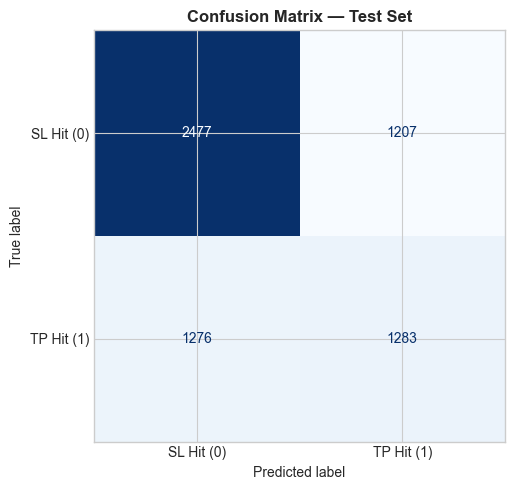

Top-left: correctly predicted SL hits (short opportunities)
Top-right: predicted TP but SL hit (false positives)
Bottom-left: predicted SL but TP hit (missed trades)
Bottom-right: correctly predicted TP hits (long opportunities)


In [6]:
test_preds = model.predict(X_test)
cm = confusion_matrix(y_test, test_preds)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['SL Hit (0)', 'TP Hit (1)']
)
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Confusion Matrix — Test Set', fontweight='bold')
plt.tight_layout()
plt.savefig('../results/04_confusion_matrix.png', dpi=120, bbox_inches='tight')
plt.show()
print("Top-left: correctly predicted SL hits (short opportunities)")
print("Top-right: predicted TP but SL hit (false positives)")
print("Bottom-left: predicted SL but TP hit (missed trades)")
print("Bottom-right: correctly predicted TP hits (long opportunities)")

## Step 6 — Feature importance (built-in)


  Top 18 feature importances:
    ret_1d_5             ████████████████████
    ret_4h_8             ████████
    ret_8                ████████
    adx_14               ████████
    rsi_dev_4h           ███████
    atr_norm             ██████
    rsi_dev_14           █████
    us10y_z20            █████
    rate_differential    ████
    ret_4                ███
    atr_roc_8            ███
    range_pos_20         ███
    vix_regime           ██
    dxy_slope            ██
    ret_24               ██
    ret_1_z24            
    us10y_direction      
    session              


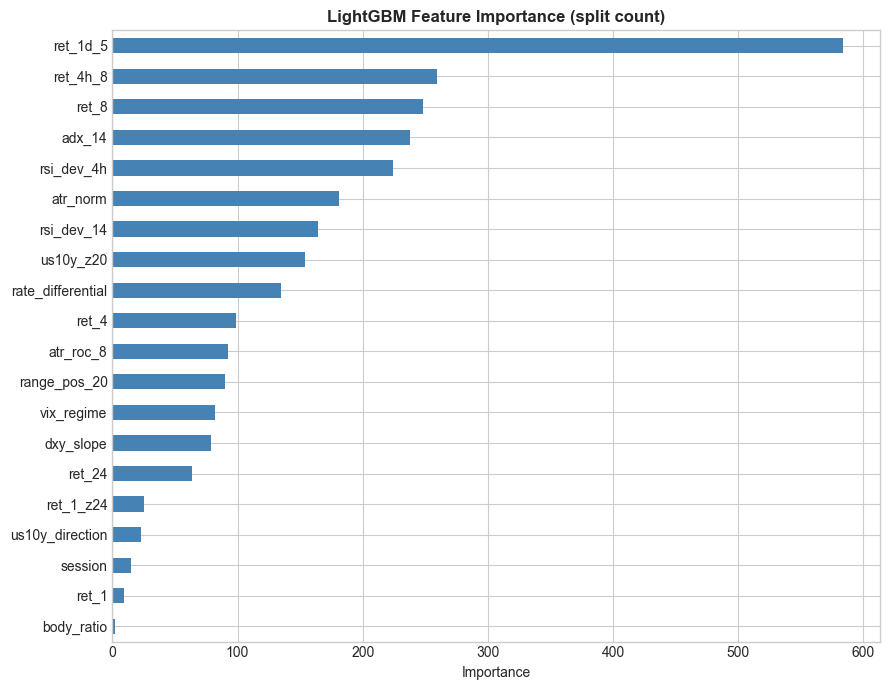

In [7]:
print_feature_importance(model, FEATURE_COLS, top_n=18)

# Plot feature importance
importances = pd.Series(model.feature_importances_, index=FEATURE_COLS).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(9, 7))
importances.plot(kind='barh', ax=ax, color='steelblue', edgecolor='none')
ax.set_title('LightGBM Feature Importance (split count)', fontweight='bold')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.savefig('../results/04_feature_importance.png', dpi=120, bbox_inches='tight')
plt.show()

## Step 7 — Learning curves (does more data help?)

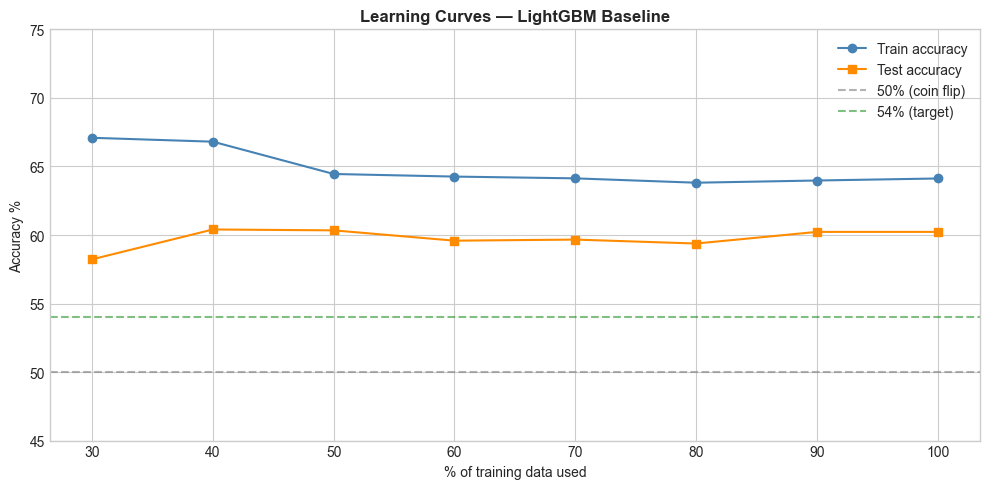

If train >> test: overfitting. If both low: underfitting or weak signal.


In [8]:
# Train on progressively more data and plot accuracy
sizes = np.linspace(0.3, 1.0, 8)
train_accs, test_accs = [], []

for size in sizes:
    n = int(len(X_train) * size)
    m_temp = build_lgbm_baseline()
    m_temp.fit(X_train.iloc[:n], y_train.iloc[:n])
    train_accs.append(m_temp.score(X_train.iloc[:n], y_train.iloc[:n]))
    test_accs.append(m_temp.score(X_test, y_test))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(sizes * 100, [a * 100 for a in train_accs], 'o-', label='Train accuracy', color='steelblue')
ax.plot(sizes * 100, [a * 100 for a in test_accs],  's-', label='Test accuracy',  color='darkorange')
ax.axhline(50, linestyle='--', color='gray',  alpha=0.6, label='50% (coin flip)')
ax.axhline(54, linestyle='--', color='green', alpha=0.5, label='54% (target)')
ax.set_xlabel('% of training data used')
ax.set_ylabel('Accuracy %')
ax.set_title('Learning Curves — LightGBM Baseline', fontweight='bold')
ax.legend()
ax.set_ylim(45, 75)
plt.tight_layout()
plt.savefig('../results/04_learning_curves.png', dpi=120, bbox_inches='tight')
plt.show()
print("If train >> test: overfitting. If both low: underfitting or weak signal.")

## Step 8 — Save model

In [9]:
save_model(model, 'lgbm_baseline.pkl')
print("\nModel saved. Can be loaded in other notebooks via:")
print("  from src.models import load_model")
print("  model = load_model('lgbm_baseline.pkl')")

  [SAVED] Model saved to: C:\Users\omtej\Projects\2020_algo_based\models\lgbm_baseline.pkl

Model saved. Can be loaded in other notebooks via:
  from src.models import load_model
  model = load_model('lgbm_baseline.pkl')


## ✅ Checkpoint — What to look for

| Metric | What it means | Action |
|---|---|---|
| Train acc > 70%, Test < 50% | Lookahead bias | Check shift(+1) on all features |
| Both train and test ~50% | Clean pipeline, no edge yet | Normal at this stage |
| Test acc 52–54% | Early signal detected | Proceed to walk-forward |
| Test acc > 55% | Strong signal | Double-check for leakage first |
| Train-test gap > 10% | Overfitting | Reduce max_depth to 4 |

**Do not be discouraged if OOS accuracy is 50-52% here.** That is the correct baseline for a clean pipeline. The walk-forward in Notebook 05 will give you the definitive answer.

**→ Open `05_walk_forward_validation.ipynb` next.**